In [41]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


In [6]:
df = pd.read_csv(r'E:\NextGen\hotel_bookings.csv')

In [7]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [8]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [11]:
df.shape

(119390, 32)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [16]:
df.describe(include="O")

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [12]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

# handling Missing Values

In [13]:
df = df.drop(['company'], axis=1)

In [17]:
df['agent'] = df['agent'].fillna(0)

In [22]:
df['country'] = df['country'].fillna('unknown')

In [24]:
df['children'] = df['children'].fillna(0)

In [25]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces 

In [27]:
df.duplicated().sum()

np.int64(32001)

In [28]:
df = df.drop_duplicates()

In [29]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000,87389.000000
mean,0.274920,79.897195,2016.210313,26.837760,15.815698,1.005321,2.625548,1.875842,0.138644,0.010825,0.039078,0.030416,0.184005,0.271625,81.008193,0.749625,106.339070,0.084233,0.698589
std,0.446477,86.053274,0.686094,13.674352,8.835244,1.031935,2.053591,0.626490,0.455888,0.113601,0.193782,0.369160,1.731962,0.727270,109.946820,10.016130,55.013097,0.281544,0.831950
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,11.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,72.000000,0.000000,0.000000
50%,0.000000,49.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,98.100000,0.000000,0.000000
75%,1.000000,125.000000,2017.000000,37.000000,23.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,0.000000,134.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,391.000000,5400.000000,8.000000,5.000000


In [30]:
df = df. drop(['reservation_status', 'reservation_status_date'], axis=1)

# Feature Engineering

In [32]:
df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

df['total_guests'] = df['adults'] + df['children'] + df['babies']

df['has_special_requests'] = (df['total_of_special_requests'] > 0).astype(int)

df['has_car_parking'] = (df['required_car_parking_spaces'] > 0).astype(int)

df['has_previous_cancellations'] = (df['previous_cancellations'] > 0).astype(int)

df['changes_per_lead_time'] = df['booking_changes'] / (df['lead_time'] + 1)

print("Features added successfully! New shape:", df.shape)


Features added successfully! New shape: (87389, 35)


# Visualization of the distribution of bookings by hotel type

In [35]:
import seaborn as sns

In [34]:
columns = []
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        columns.append(col)
correlation_matrix = df[columns].corr()

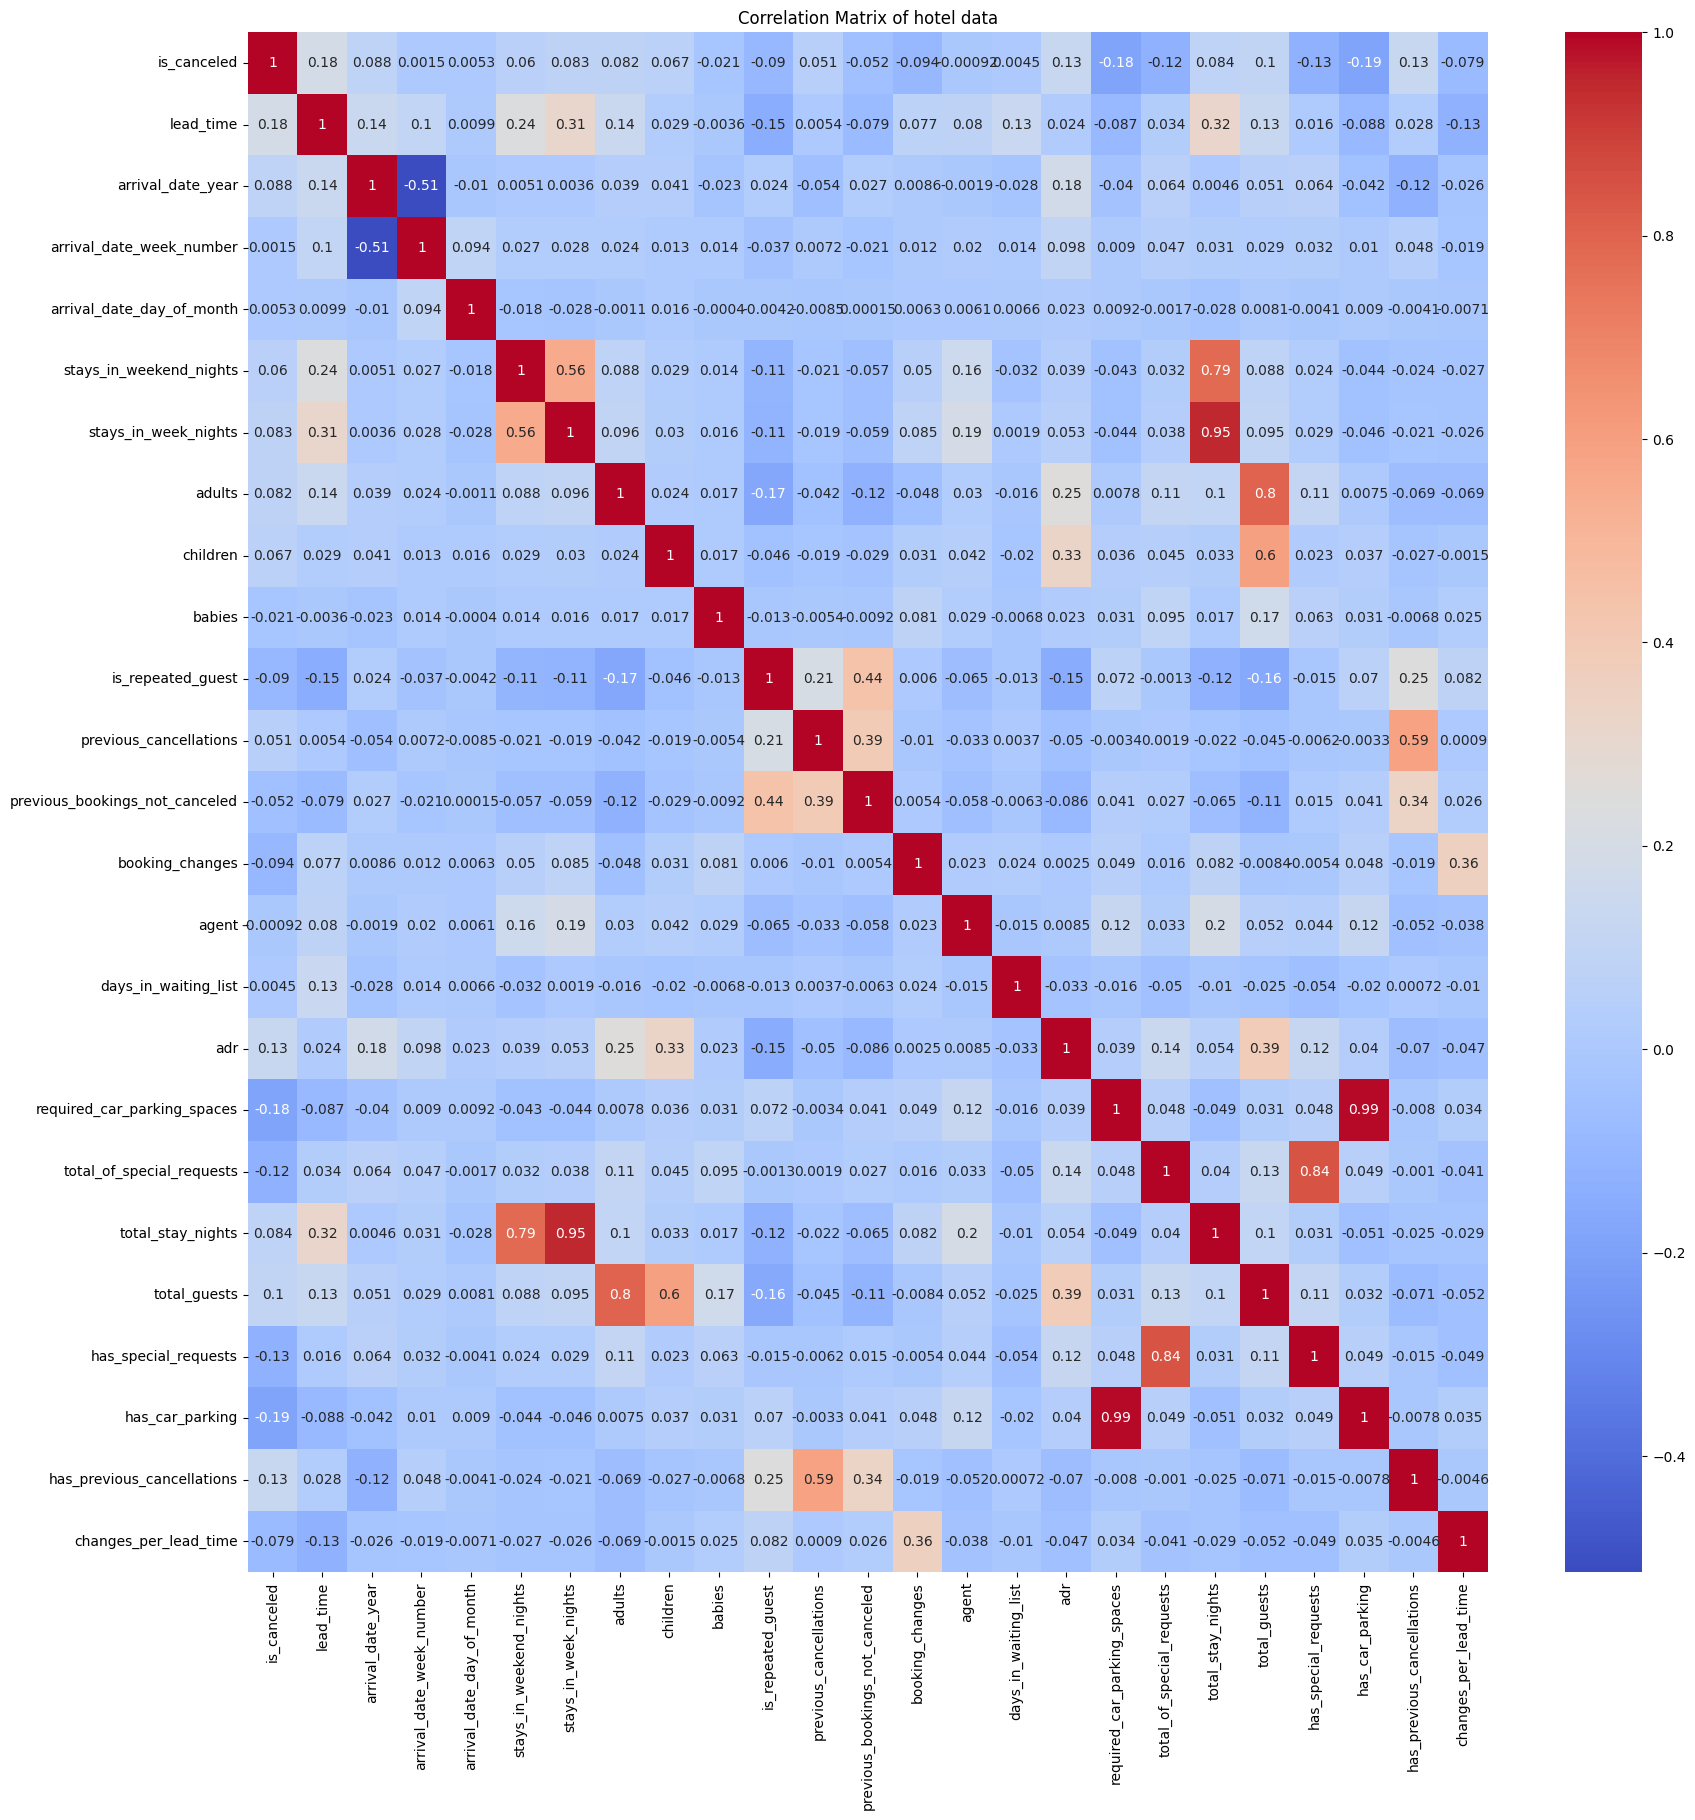

In [44]:
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title('Correlation Matrix of hotel data')
plt.show()

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

In [46]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [48]:
numerical_cols = X_train.select_dtypes(include=['int64', 'float64', 'int32', 'float32']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])

In [49]:
models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

In [50]:
results = []
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4)
    })

results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print(results_df.to_string(index=False))

              Model  Accuracy  ROC-AUC  F1-Score
      Random Forest    0.8460   0.9067    0.6916
  Gradient Boosting    0.8256   0.8858    0.6387
Logistic Regression    0.7998   0.8506    0.5786
   Baseline (Dummy)    0.7251   0.5000    0.0000


In [51]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

In [52]:
best_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
best_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['lead_time',
                                                   'arrival_date_year',
                                                   'arrival_date_week_number',
                                                   'arrival_date_day_of_month',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                                                   'babies',
                                                   'is_repeated_guest',
                                                   'previous_cancellations',
                                                   'previous_bookings_not_canceled',
                                                   'booking_changes',...
                                                   'has_previous_cancellations',
                                                   'changes_per_lead_time']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['hotel',
                                                   'arrival_date_month', 'meal',
                                                   'country', 'market_segment',
                                                   'distribution_channel',
                                                   'reserved_room_type',
                                                   'assigned_room_type',
                                                   'deposit_type',
                                                   'customer_type'])])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])

In [53]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Confirmed (0)', 'Canceled (1)']))

--- Classification Report ---
               precision    recall  f1-score   support

Confirmed (0)       0.87      0.93      0.90     12673
 Canceled (1)       0.77      0.63      0.69      4805

     accuracy                           0.85     17478
    macro avg       0.82      0.78      0.79     17478
 weighted avg       0.84      0.85      0.84     17478



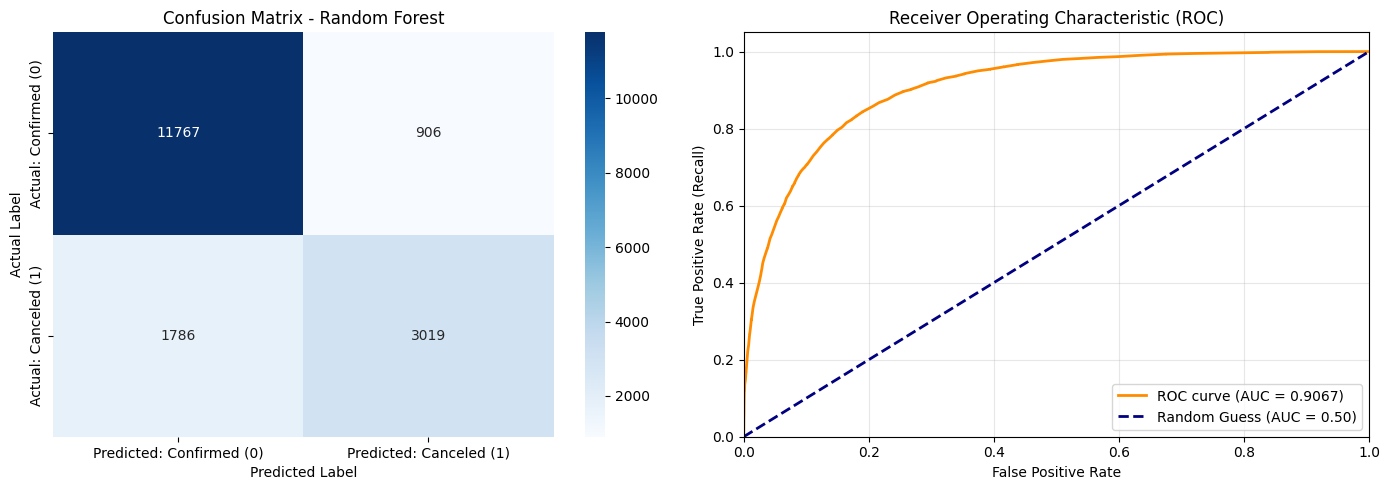

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Predicted: Confirmed (0)', 'Predicted: Canceled (1)'],
            yticklabels=['Actual: Confirmed (0)', 'Actual: Canceled (1)'])
axes[0].set_title('Confusion Matrix - Random Forest')
axes[0].set_ylabel('Actual Label')
axes[0].set_xlabel('Predicted Label')

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Save Model

In [65]:
import joblib

joblib.dump(best_model, "hotel_cancellation_model.joblib")
print("Model saved successfully as 'hotel_cancellation_model.joblib'!")

Model saved successfully as 'hotel_cancellation_model.joblib'!


# Streemlit

In [ ]:
app_code = """import streamlit as st
import pandas as pd
import joblib

# Load the saved model
model = joblib.load('hotel_cancellation_model.joblib')

st.set_page_config(page_title="Hotel Cancellation Predictor", layout="centered")

st.title("Hotel Revenue Protection: Cancellation Predictor")
st.write("Enter the booking details below to check the probability of cancellation and the recommended policy to protect hotel revenue.")

with st.form("prediction_form"):
    col1, col2 = st.columns(2)
    
    with col1:
        hotel = st.selectbox("Hotel Type", ["City Hotel", "Resort Hotel"])
        lead_time = st.number_input("Lead Time (Days)", min_value=0, max_value=737, value=30)
        adr = st.number_input("Average Daily Rate (ADR)", min_value=0.0, value=100.0)
        market_segment = st.selectbox("Market Segment", ["Online TA", "Offline TA/TO", "Direct", "Corporate", "Groups"])
        deposit_type = st.selectbox("Deposit Type", ["No Deposit", "Non Refund", "Refundable"])
        
    with col2:
        adults = st.number_input("Adults", min_value=1, max_value=10, value=2)
        children = st.number_input("Children", min_value=0, max_value=10, value=0)
        babies = st.number_input("Babies", min_value=0, max_value=5, value=0)
        stays_in_week_nights = st.number_input("Week Nights", min_value=0, max_value=50, value=2)
        stays_in_weekend_nights = st.number_input("Weekend Nights", min_value=0, max_value=20, value=1)
        total_of_special_requests = st.slider("Special Requests", min_value=0, max_value=5, value=0)
        previous_cancellations = st.number_input("Previous Cancellations", min_value=0, max_value=20, value=0)

    submit_button = st.form_submit_button(label="Predict Booking Status")

if submit_button:
    input_data = pd.DataFrame({
        'hotel': [hotel],
        'lead_time': [lead_time],
        'arrival_date_year': [2016],
        'arrival_date_month': ['July'],
        'arrival_date_week_number': [27],
        'arrival_date_day_of_month': [15],
        'stays_in_weekend_nights': [stays_in_weekend_nights],
        'stays_in_week_nights': [stays_in_week_nights],
        'adults': [adults],
        'children': [children],
        'babies': [babies],
        'meal': ['BB'],
        'country': ['PRT'],
        'market_segment': [market_segment],
        'distribution_channel': ['TA/TO' if 'TA' in market_segment else 'Direct'],
        'is_repeated_guest': [0],
        'previous_cancellations': [previous_cancellations],
        'previous_bookings_not_canceled': [0],
        'reserved_room_type': ['A'],
        'assigned_room_type': ['A'],
        'booking_changes': [0],
        'deposit_type': [deposit_type],
        'agent': [9.0 if 'TA' in market_segment else 0.0],
        'days_in_waiting_list': [0],
        'customer_type': ['Transient'],
        'adr': [adr],
        'required_car_parking_spaces': [0],
        'total_of_special_requests': [total_of_special_requests],
        # Feature Engineering columns added during training
        'total_stay_nights': [stays_in_weekend_nights + stays_in_week_nights],
        'total_guests': [adults + children + babies],
        'has_special_requests': [1 if total_of_special_requests > 0 else 0],
        'has_car_parking': [0],
        'has_previous_cancellations': [1 if previous_cancellations > 0 else 0],
        'changes_per_lead_time': [0.0]
    })
    
    # Prediction
    prediction = model.predict(input_data)[0]
    probability = model.predict_proba(input_data)[0][1] * 100
    
    st.markdown("---")
    st.subheader("Analysis and Prediction Result:")
    
    if prediction == 1:
        st.error(f"Warning: High probability of cancellation! (Probability: {probability:.1f}%)")
        st.info("Recommendation for the Hotel: Require full deposit or a non-refundable policy to protect revenue.")
    else:
        st.success(f"Booking is stable and likely to be confirmed (Expected cancellation probability: {probability:.1f}%)")
        st.info("Recommendation for the Hotel: Allow booking without advance deposit.")
"""

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("app.py created successfully in your project folder!")

app.py created successfully in your project folder!
